# EDA del corpus documental

Calidad de extracción, longitudes de texto y cobertura por aspectos.

Orden de cobertura: **(A) hits/densidad → (B) TF-IDF → (C) etiqueta de corte**. Cada bloque se interpreta por separado.


In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

import pandas as pd
import matplotlib.pyplot as plt

INV = ROOT / "data" / "processed" / "corpus" / "inventario_documental.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INV)
for col in ("n_pages", "chars", "words"):
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)


## Calidad de extracción


estado_extraccion
ok                 11
weak_or_scanned     1
Name: count, dtype: int64
texto_extraible:
texto_extraible
True    12
Name: count, dtype: int64


,doc_id,words,chars,estado_extraccion,notas
9,D010,128,819,weak_or_scanned,NaN


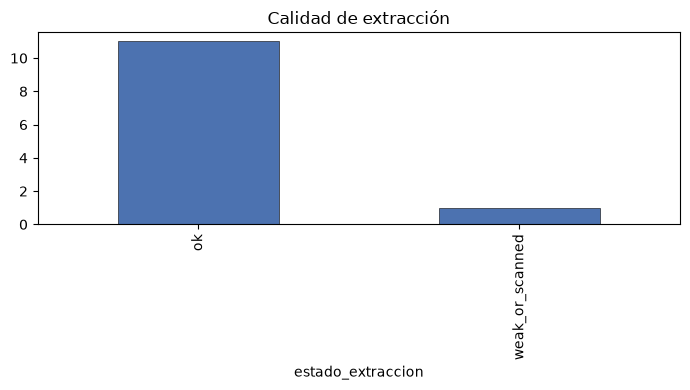

In [2]:
print(df["estado_extraccion"].value_counts())
print("texto_extraible:")
print(df["texto_extraible"].value_counts())
d010 = df[df["doc_id"] == "D010"]
if not d010.empty:
    display(d010[["doc_id", "words", "chars", "estado_extraccion", "notas"]])
else:
    print("D010 no está en el inventario.")

fig, ax = plt.subplots(figsize=(7, 4))
df["estado_extraccion"].value_counts().plot(
    kind="bar", ax=ax, color="#4C72B0", edgecolor="black", linewidth=0.4
)
ax.set_title("Calidad de extracción")
ax.set_xlabel("estado_extraccion")
fig.tight_layout()
p = FIG_DIR / "eda_calidad_extraccion.png"
fig.savefig(p, dpi=140)
plt.show()


## Longitudes de texto


,n_pages,chars,words
count,12.000000,12.000000,12.000000
mean,8.500000,27874.416667,4060.833333
std,6.403124,20115.536634,2957.720309
min,1.000000,819.000000,128.000000
25%,4.500000,13118.000000,1967.750000
50%,7.500000,22037.500000,3177.000000
75%,11.500000,47365.250000,6913.750000
max,20.000000,57927.000000,8623.000000


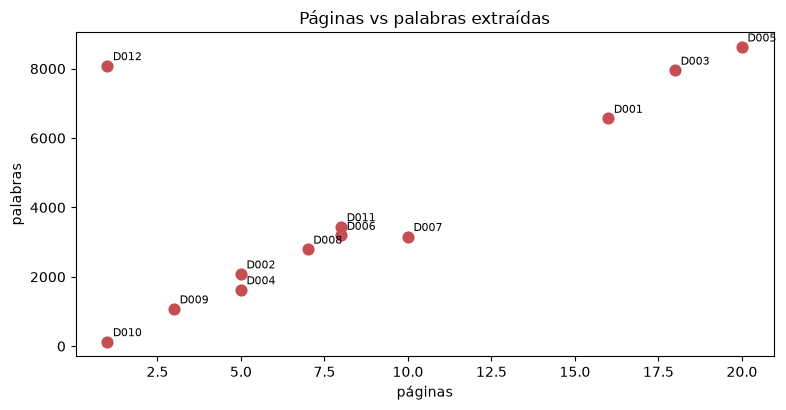

In [3]:
display(df[["doc_id", "n_pages", "chars", "words"]].describe())

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df["n_pages"], df["words"], s=60, c="#C44E52")
for _, r in df.iterrows():
    ax.annotate(
        r["doc_id"],
        (r["n_pages"], r["words"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.set_title("Páginas vs palabras extraídas")
ax.set_xlabel("páginas")
ax.set_ylabel("palabras")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_paginas_vs_palabras.png", dpi=140)
plt.show()


## Cobertura documental: aspectos

Antes de las métricas se definen **aspectos** (procesos o subtemas), no un tema genérico.
Ejemplo: matrícula de inscripción y anulación/retiro se miden por separado.


In [4]:
from thesis_routing.eda.coverage_aspects import (
    ASPECT_SPECS,
    MIN_DENSIDAD_POR_1K,
    MIN_HITS,
    MIN_TFIDF_COSINE,
    MIN_WORDS_DOC,
    build_coverage_bundle,
)

TEXT_DIR = ROOT / "data" / "interim" / "extracted_text"

print("Aspectos (filtrar/proceso, no solo la palabra genérica):")
for name, spec in ASPECT_SPECS.items():
    print(f"  - {name}")
    print(f"      query TF-IDF: {spec['query']}")

bundle = build_coverage_bundle(TEXT_DIR, df, FIG_DIR)
print("\nBundle calculado (hits, densidad, tfidf, etiquetas).")


Aspectos (filtrar/proceso, no solo la palabra genérica):
  - matricula_inscripcion
      query TF-IDF: matricula inscripción proceso matrícula regular
  - anulacion_retiro
      query TF-IDF: anulación matrícula retiro asignatura
  - asistencia_inasistencia
      query TF-IDF: asistencia inasistencias porcentaje sesiones
  - evaluacion_examenes
      query TF-IDF: examen parcial final sustitutorio evaluación aplazados
  - creditos_academicos
      query TF-IDF: créditos académicos crédito
  - prerrequisitos
      query TF-IDF: prerrequisito prerrequisitos
  - convalidacion
      query TF-IDF: convalidación convalidar estudios
  - aprobacion_desaprobacion
      query TF-IDF: aprobación desaprobación nota mínima
  - tramites_grados_titulos
      query TF-IDF: bachiller título profesional grados títulos
  - becas
      query TF-IDF: beca becas beneficio económico
  - admision
      query TF-IDF: admisión postulante examen admisión
  - tarifas_pensiones
      query TF-IDF: tarifario pensió


Bundle calculado (hits, densidad, tfidf, etiquetas).


## A. Hits y densidad (presencia lexical)

**Para qué:** contar si el patrón del aspecto aparece y con qué intensidad relativa al tamaño del documento.

- `hits`: conteo crudo del patrón
- `densidad_1k`: hits por 1000 palabras (corrige documentos largos)

Este bloque no usa TF-IDF. Solo presencia lexical cuantificada.


A1. Hits (conteo crudo)


,D001,D002,D003,D004,D005,D006,D007,D008,D009,D010,D011,D012
aspecto,,,,,,,,,,,,
matricula_inscripcion,4,9,1,6,2,29,0,0,0,3,10,7
anulacion_retiro,0,1,0,1,1,0,0,0,0,0,1,1
asistencia_inasistencia,9,0,5,0,0,1,2,3,0,0,0,9
evaluacion_examenes,10,0,0,0,0,0,0,1,0,0,3,6
creditos_academicos,9,7,2,4,2,3,5,0,4,1,2,9
prerrequisitos,0,1,0,0,0,0,0,0,2,0,0,0
convalidacion,6,3,0,0,0,5,0,0,23,0,6,2
aprobacion_desaprobacion,4,9,1,0,41,2,9,6,0,0,0,4
tramites_grados_titulos,4,0,14,0,104,1,0,0,0,0,23,16


A2. Densidad por 1000 palabras


,D001,D002,D003,D004,D005,D006,D007,D008,D009,D010,D011,D012
aspecto,,,,,,,,,,,,
matricula_inscripcion,0.609,4.323,0.126,3.692,0.232,9.082,0.000,0.000,0.000,23.438,2.904,0.866
anulacion_retiro,0.000,0.480,0.000,0.615,0.116,0.000,0.000,0.000,0.000,0.000,0.290,0.124
asistencia_inasistencia,1.370,0.000,0.629,0.000,0.000,0.313,0.633,1.073,0.000,0.000,0.000,1.113
evaluacion_examenes,1.523,0.000,0.000,0.000,0.000,0.000,0.000,0.358,0.000,0.000,0.871,0.742
creditos_academicos,1.370,3.362,0.251,2.462,0.232,0.940,1.582,0.000,3.724,7.812,0.581,1.113
prerrequisitos,0.000,0.480,0.000,0.000,0.000,0.000,0.000,0.000,1.862,0.000,0.000,0.000
convalidacion,0.914,1.441,0.000,0.000,0.000,1.566,0.000,0.000,21.415,0.000,1.743,0.247
aprobacion_desaprobacion,0.609,4.323,0.126,0.000,4.755,0.626,2.847,2.147,0.000,0.000,0.000,0.495
tramites_grados_titulos,0.609,0.000,1.760,0.000,12.061,0.313,0.000,0.000,0.000,0.000,6.680,1.979


A3. Gráficos de presencia lexical
Heatmap de hits:


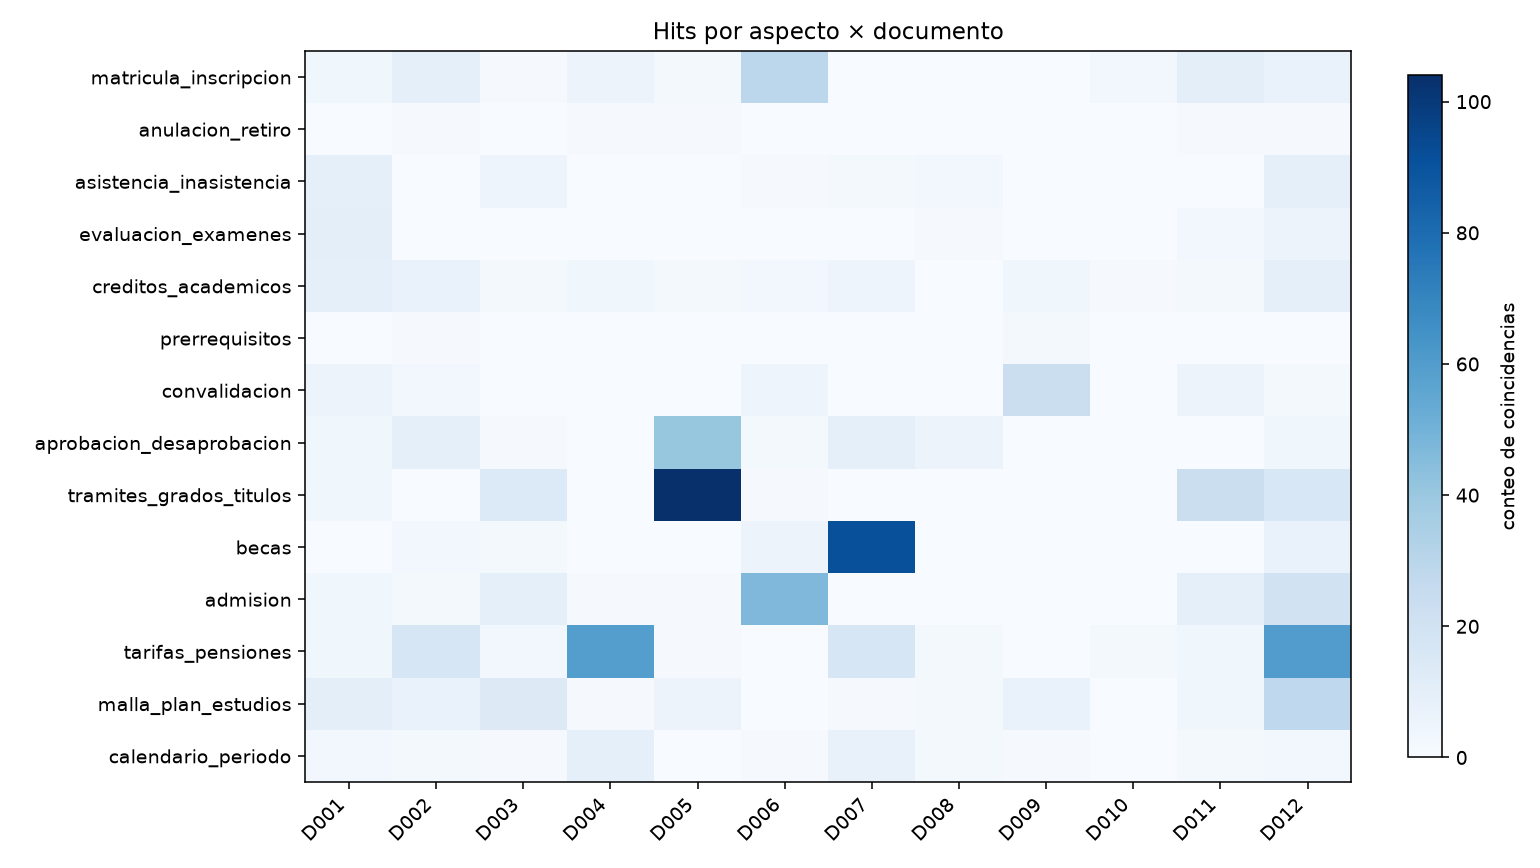

Heatmap de densidad / 1000 palabras:


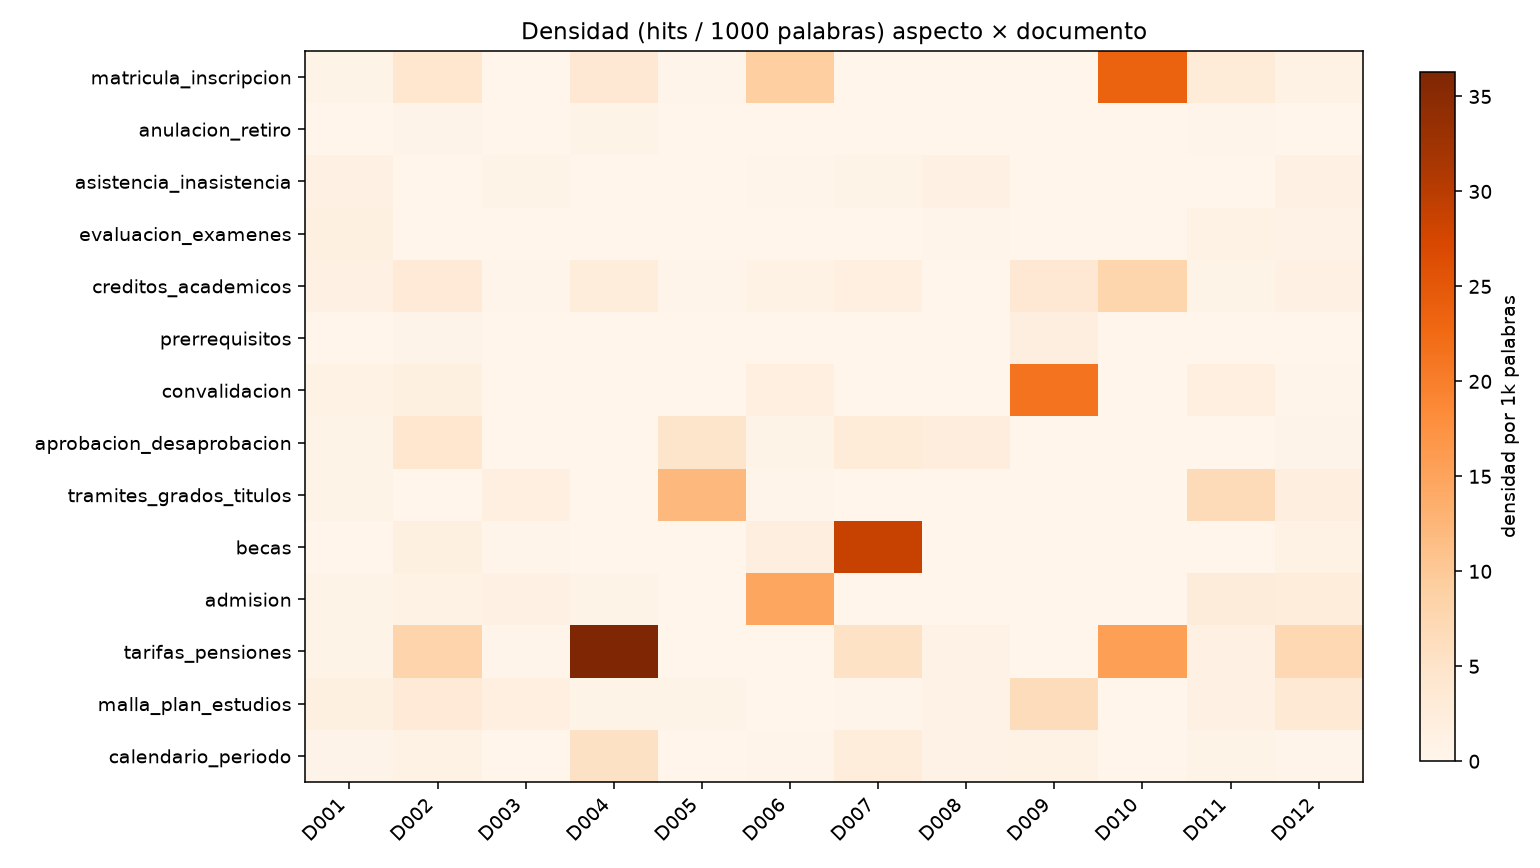

In [5]:
from IPython.display import Image, display as idisplay

print("A1. Hits (conteo crudo)")
display(bundle["hits"])

print("A2. Densidad por 1000 palabras")
display(bundle["densidad"])

print("A3. Gráficos de presencia lexical")
for name, title in (
    ("eda_cobertura_hits.png", "Heatmap de hits"),
    ("eda_cobertura_densidad.png", "Heatmap de densidad / 1000 palabras"),
):
    p = FIG_DIR / name
    print(title + ":")
    if p.exists():
        idisplay(Image(filename=str(p)))
    else:
        print("  no encontrado:", p)


## B. TF-IDF (relevancia relativa)

**Para qué:** medir qué tan afín es cada documento a la consulta del aspecto, frente al resto del corpus.

No es lo mismo un documento donde el aspecto es central que uno con una mención débil.
El heatmap muestra la similitud cosine TF-IDF (número continuo).

Este bloque se lee aparte de los hits.


B1. Matriz TF-IDF cosine (aspecto × documento)


,D001,D002,D003,D004,D005,D006,D007,D008,D009,D010,D011,D012
matricula_inscripcion,0.0203,0.0620,0.0077,0.0603,0.0089,0.0363,0.0181,0.0050,0.0198,0.0337,0.0350,0.0165
anulacion_retiro,0.0104,0.0369,0.0028,0.0351,0.0052,0.0190,0.0174,0.0069,0.0083,0.0253,0.0181,0.0151
asistencia_inasistencia,0.0347,0.0000,0.0121,0.0209,0.0059,0.0038,0.0214,0.0141,0.0000,0.0000,0.0000,0.0185
evaluacion_examenes,0.0477,0.0023,0.0049,0.0043,0.0124,0.0153,0.0106,0.0218,0.0100,0.0000,0.0202,0.0282
creditos_academicos,0.0171,0.0154,0.0091,0.0229,0.0072,0.0111,0.0350,0.0000,0.0199,0.0217,0.0161,0.0173
prerrequisitos,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0297,0.0000,0.0000,0.0000
convalidacion,0.0141,0.0187,0.0059,0.0033,0.0051,0.0190,0.0056,0.0000,0.0922,0.0000,0.0208,0.0061
aprobacion_desaprobacion,0.0215,0.0128,0.0022,0.0000,0.0274,0.0106,0.0073,0.0097,0.0122,0.0134,0.0000,0.0049
tramites_grados_titulos,0.0393,0.0086,0.0435,0.0000,0.0690,0.0219,0.0066,0.0112,0.0000,0.0000,0.0597,0.0429
becas,0.0000,0.0251,0.0052,0.0248,0.0000,0.0224,0.0802,0.0000,0.0000,0.0000,0.0048,0.0200


B2. Heatmap TF-IDF


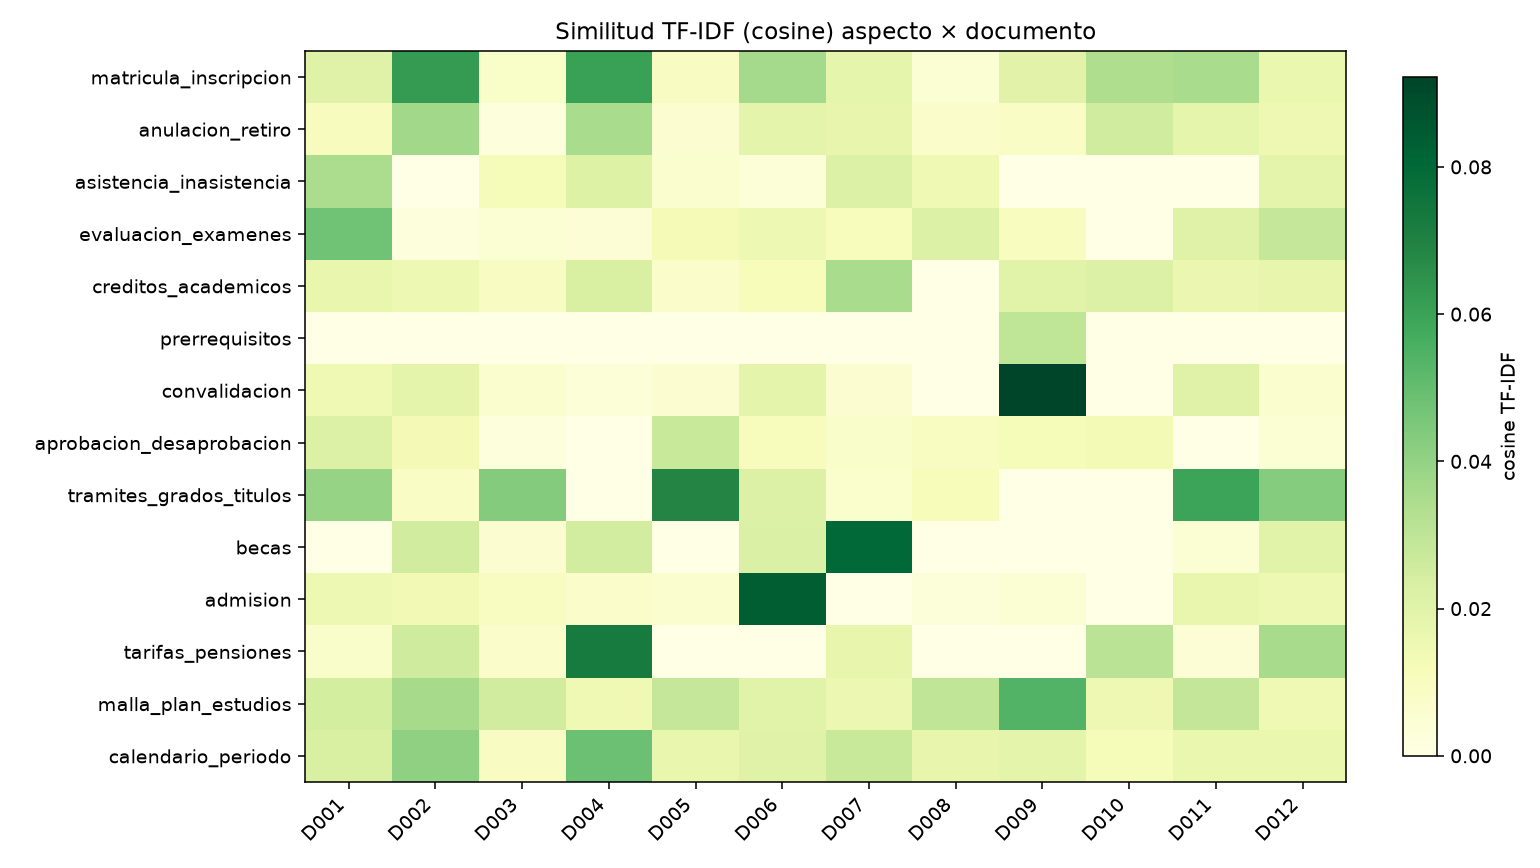

B3. Barras TF-IDF (top aspectos)


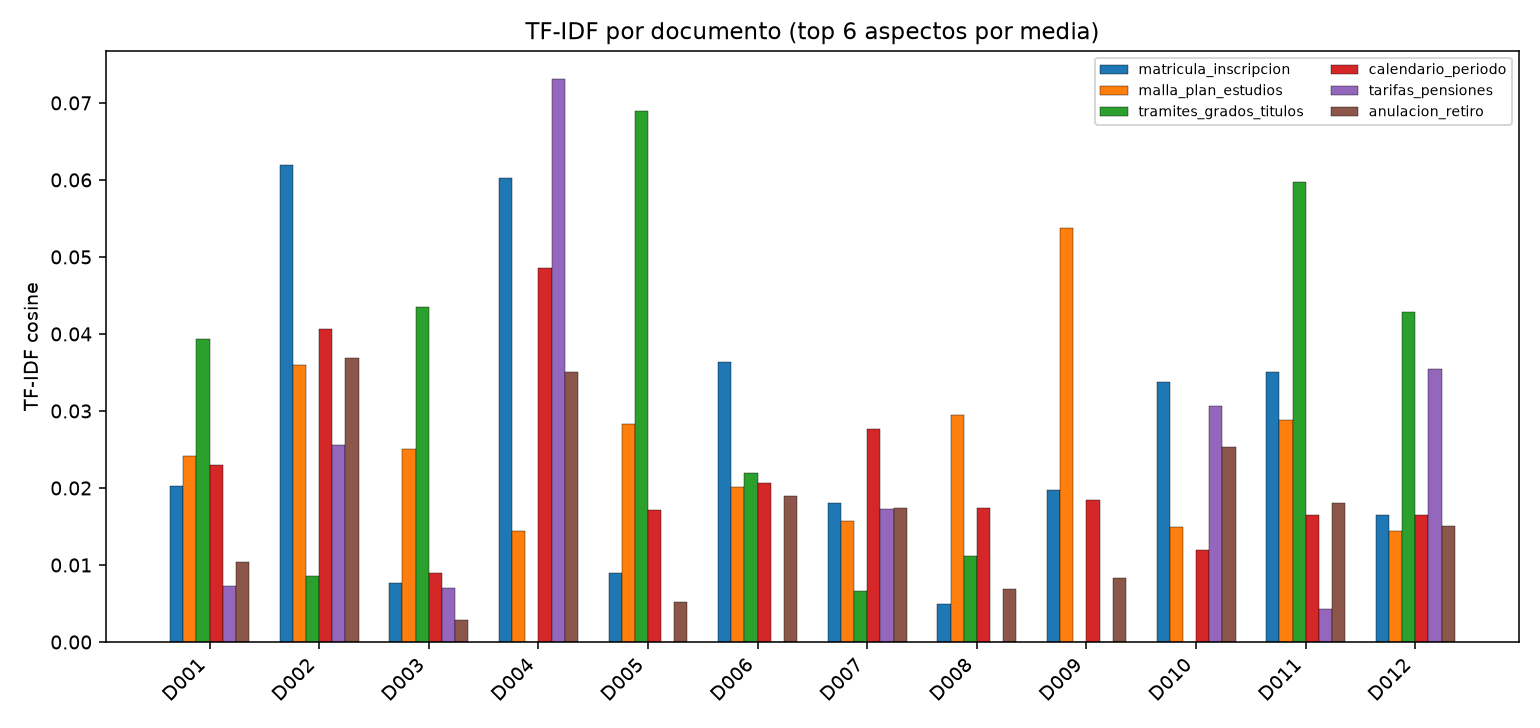

In [6]:
print("B1. Matriz TF-IDF cosine (aspecto × documento)")
display(bundle["tfidf"])

print("B2. Heatmap TF-IDF")
p_heat = FIG_DIR / "eda_cobertura_tfidf.png"
if p_heat.exists():
    idisplay(Image(filename=str(p_heat)))
else:
    print("no encontrado:", p_heat)

print("B3. Barras TF-IDF (top aspectos)")
p_bars = FIG_DIR / "eda_cobertura_tfidf_barras.png"
if p_bars.exists():
    idisplay(Image(filename=str(p_bars)))
else:
    print("no encontrado:", p_bars)


## C. Etiqueta de corte

Hits y TF-IDF ya se presentaron por separado. Aquí se aplica una regla binaria `cubierto` / `no_cubierto`.

Umbrales:

- `MIN_WORDS_DOC`: el documento debe tener texto suficiente
- luego: `(hits >= MIN_HITS y dens_1k >= MIN_DENSIDAD) o (tfidf >= MIN_TFIDF)`


Umbrales de la etiqueta:
  MIN_WORDS_DOC = 300
  MIN_HITS = 3
  MIN_DENSIDAD_POR_1K = 0.4
  MIN_TFIDF_COSINE = 0.04

C1. Etiqueta binaria


,D001,D002,D003,D004,D005,D006,D007,D008,D009,D010,D011,D012
aspecto,,,,,,,,,,,,
matricula_inscripcion,cubierto,cubierto,no_cubierto,cubierto,no_cubierto,cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto,cubierto
anulacion_retiro,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto
asistencia_inasistencia,cubierto,no_cubierto,cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto
evaluacion_examenes,cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto,cubierto
creditos_academicos,cubierto,cubierto,no_cubierto,cubierto,no_cubierto,cubierto,cubierto,no_cubierto,cubierto,no_cubierto,no_cubierto,cubierto
prerrequisitos,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto
convalidacion,cubierto,cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto,no_cubierto,no_cubierto,cubierto,no_cubierto,cubierto,no_cubierto
aprobacion_desaprobacion,cubierto,cubierto,no_cubierto,no_cubierto,cubierto,no_cubierto,cubierto,cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto
tramites_grados_titulos,cubierto,no_cubierto,cubierto,no_cubierto,cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,no_cubierto,cubierto,cubierto


C2. Resumen: docs cubiertos por aspecto


,aspecto,docs_cubiertos,docs_total,pct_docs
0,matricula_inscripcion,6,12,50.0
1,anulacion_retiro,0,12,0.0
2,asistencia_inasistencia,4,12,33.3
3,evaluacion_examenes,3,12,25.0
4,creditos_academicos,7,12,58.3
5,prerrequisitos,0,12,0.0
6,convalidacion,5,12,41.7
7,aprobacion_desaprobacion,6,12,50.0
8,tramites_grados_titulos,5,12,41.7
9,becas,4,12,33.3


C3. Gráfico resumen (% docs cubiertos)


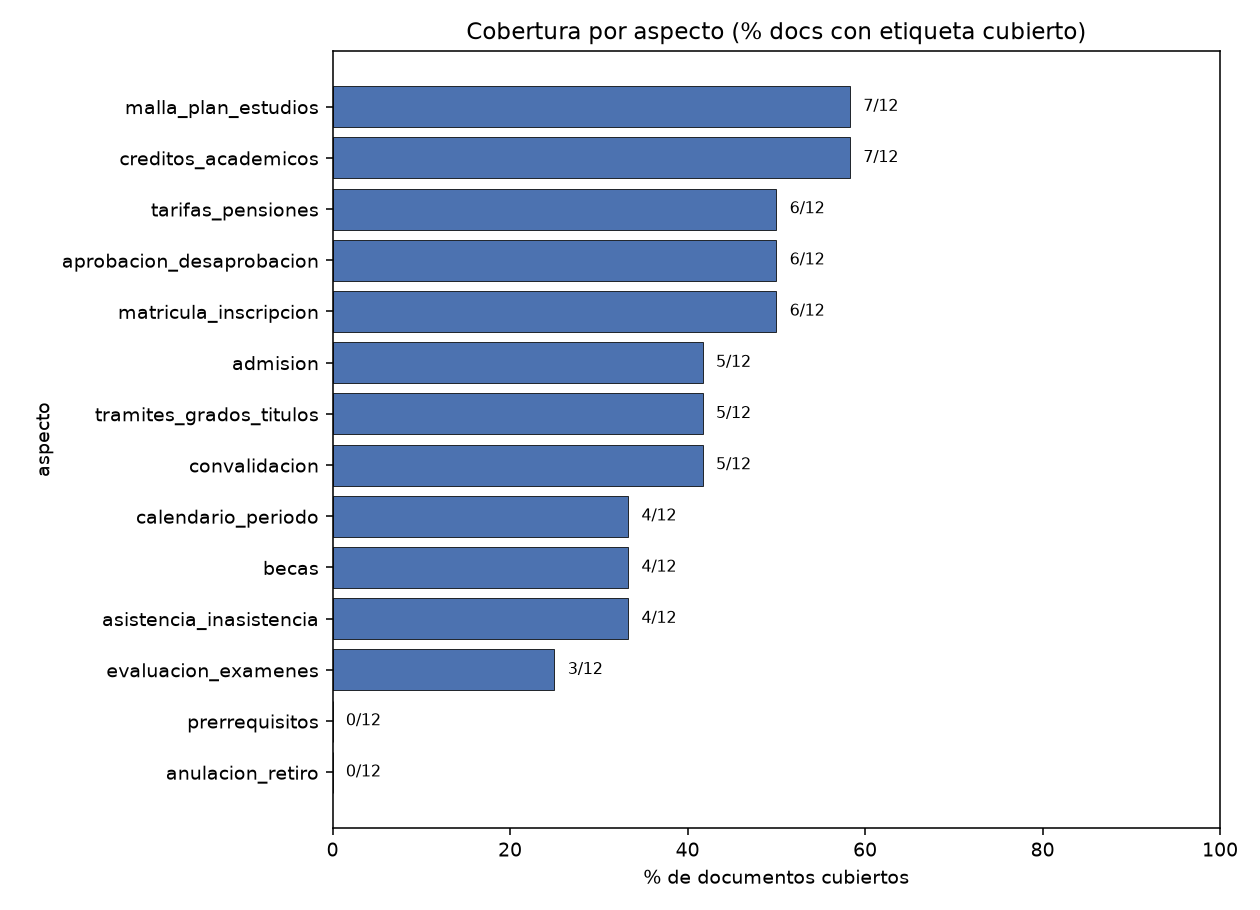

Archivos de figura en reports/figures/:
  OK: eda_cobertura_hits.png
  OK: eda_cobertura_densidad.png
  OK: eda_cobertura_tfidf.png
  OK: eda_cobertura_tfidf_barras.png
  OK: eda_cobertura_resumen_barras.png


In [7]:
print("Umbrales de la etiqueta:")
print(f"  MIN_WORDS_DOC = {MIN_WORDS_DOC}")
print(f"  MIN_HITS = {MIN_HITS}")
print(f"  MIN_DENSIDAD_POR_1K = {MIN_DENSIDAD_POR_1K}")
print(f"  MIN_TFIDF_COSINE = {MIN_TFIDF_COSINE}")

print("\nC1. Etiqueta binaria")
display(bundle["etiquetas"])

print("C2. Resumen: docs cubiertos por aspecto")
display(bundle["resumen"])

print("C3. Gráfico resumen (% docs cubiertos)")
p_sum = FIG_DIR / "eda_cobertura_resumen_barras.png"
if p_sum.exists():
    idisplay(Image(filename=str(p_sum)))
else:
    print("no encontrado:", p_sum)

print("Archivos de figura en reports/figures/:")
for name in (
    "eda_cobertura_hits.png",
    "eda_cobertura_densidad.png",
    "eda_cobertura_tfidf.png",
    "eda_cobertura_tfidf_barras.png",
    "eda_cobertura_resumen_barras.png",
):
    p = FIG_DIR / name
    print(f"  {'OK' if p.exists() else 'FALTA'}: {name}")


## Lectura e implicaciones

### Cómo leer el orden

1. **A (hits/densidad):** ¿aparece el aspecto? ¿con qué intensidad relativa?
2. **B (TF-IDF):** ¿qué tan relevante es el documento para ese aspecto?
3. **C (etiqueta):** corte binario para decidir; no sustituye a A ni B.

### Interpretación

- La cobertura se reporta con métricas numéricas y etiqueta binaria (`cubierto` / `no_cubierto`).
- Los aspectos separan procesos (matrícula vs anulación, convalidación vs aprobación, etc.).
- TF-IDF diferencia documentos donde el aspecto es central de menciones débiles.
- Cobertura textual no equivale a vigencia jurídica ni a calidad de respuesta del sistema.

### Decisiones

| Decisión | Por qué |
|----------|--------|
| Índice A1: D001–D009, D011, D012 | Extracción usable y aspectos con evidencia en A/B |
| Aislar D010 | Poco texto; no sostiene cobertura operativa |
| Prerrequisitos / malla oficial con cautela | Aspectos suelen salir débiles o `no_cubierto` |

### Criterio de cobertura

| Elemento | Estado en este EDA |
|----------|-------------------|
| Regla numérica explícita (sin etiquetas ambiguas) | Aplicada |
| Separación por aspectos / subprocesos | Aplicada |
| Relevancia TF-IDF reportada aparte de los hits | Aplicada |
| Revisión manual párrafo a párrafo | Fuera del alcance de este piloto |
